# [WEEK 7] A/B Test Design — Assignment (학생용)

**과제 유형: B. 도구 활용형** (생성형 AI 사용 가능, 판단·검증·해석은 직접)

## 과제 목적

숙박 예약 앱의 분석팀이 **"promotion 채널 사용자의 목록 → 상세 전환율이 유독 낮다"**는 진단을 넘겨줬습니다.
이번 과제에서는 이 문제를 개선할 아이디어를 **검증 가능한 실험으로 설계**하고, **여러분이 쓴 설계서 그대로 실험을 돌려** 결과를 판정합니다.

과제의 무게중심은 코드가 아니라 **설계**입니다. 설계서에 적은 값(지표, 배정 단위, 표본, 기간, 중단 규칙)이 실제 실험 결과를 결정하고, 결과를 보기 전에 정한 **판정 규칙**대로 배포 여부를 결정해야 합니다.

> **진단 메모 → 처방 선택 → 가설 → 지표 → 배정 → 표본·기간 → 사전 판정 규칙 → 실행 → SRM 확인 → 검정 → 판정**

---

## 📝 기술블로그 활용 안내

이번 글은 **"진단 결과를 받아서, 개선안을 실험으로 검증한다"**는 흐름으로 작성해주세요. 다음 그로스 세션 글과 이어지는 시리즈가 됩니다.

- **Part 0**의 Q0 답변 → 글의 도입부 ("왜 가격 표시 오류 수정은 실험하지 않고, 화면 개선만 실험했는가")
- **Part 1.2 ~ 1.7**의 설계서 → 본문 "실험 설계" 섹션 (특히 1.5의 MDE–기간 그래프와 선택 근거)
- **Part 2.2 ~ 2.3**의 결과 표·그래프와 결정 메모 → 본문 "결과와 의사결정" 섹션
- (선택) **Part 3** 심화 결과 → "설계가 달랐다면?" 섹션

코드를 나열하지 말고, **왜 그렇게 설계했고 결과를 어떻게 판정했는지**를 중심으로 써주세요.

---

## 🤖 생성형 AI 활용 안내

AI 사용은 가능합니다. 다만 이 과제는 **본인이 고른 설계값**(아이디어, 지표, 대상, 기간, 중단 규칙)에 따라 실험 결과가 달라지기 때문에, AI의 일반론으로는 답이 맞지 않습니다.

- 코드 문법, 시각화, 오류 수정, 개념 확인에 활용 가능
- 수치와 판정은 반드시 **본인 데이터로 직접 계산한 결과**로
- 마지막 셀에 **AI 활용 방법과 대화 내역**을 꼭 붙여주세요

> 이번 과제에서 가장 많이 감점되는 실수: **결과를 보고 나서 판정 기준을 바꾸는 것**입니다.

---
# 0. 환경 설정

1. 라이브러리 셀 → **실험 시뮬레이터** 셀 → **분석 도우미** 셀을 차례로 실행하세요. (세 셀 모두 수정하지 마세요)
2. 그다음 데이터 생성 셀을 실행하세요. `SEED`는 고정값이라 모두 같은 사용자 데이터를 씁니다.
   **결과를 다르게 만드는 건 여러분의 설계**입니다.

데이터는 교육용 synthetic dataset입니다. 가상의 숙박 예약 앱 로그이며, 이후 그로스 세션 과제에서도 같은 앱이 등장합니다.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [ ]:
#@title ⚙️ 실험 시뮬레이터 — 수정하지 말고 실행하세요
# 이 셀은 "실험 전 로그"와 "여러분의 설계대로 돌아가는 A/B 실험 데이터"를 만들어 줍니다.
# 가상의 숙박 예약 앱 로그입니다. (이후 그로스 세션 과제에서도 같은 앱이 등장합니다)
import json, base64, math
import numpy as np
import pandas as pd

_CFG = json.loads(base64.b64decode(
    "eyJBIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA0MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMDEs"
    "ICJyb29tX3Byb21vIjogMC4wMSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0eSI6IDAuMCwgImFtb3VudCI6IDEu"
    "MCwgImNhbmNlbCI6IDAuMH0sICJCIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA3LCAiZGV0YWlsX290aGVyIjogMC4w"
    "NDUsICJyb29tIjogLTAuMDY1LCAicm9vbV9wcm9tbyI6IC0wLjA2NSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0"
    "eSI6IDAuMCwgImFtb3VudCI6IDEuMCwgImNhbmNlbCI6IDAuMH0sICJDIjogeyJkZXRhaWxfcHJvbW8iOiAwLjAx"
    "MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMCwgInJvb21fcHJvbW8iOiAwLjAsICJjb21wbGV0"
    "ZSI6IDAuMDMsICJub3ZlbHR5IjogMC4xLCAiYW1vdW50IjogMC45MiwgImNhbmNlbCI6IDAuMDR9fQ=="
).decode())

_CHANNELS = ["organic", "paid_search", "promotion", "referral"]
_CH_P = [0.38, 0.27, 0.20, 0.15]
_DEVICES = ["android", "ios", "web"]
_DV_P = [0.41, 0.38, 0.21]
_P_LIST = 0.925
_P_DETAIL = {"organic": 0.62, "paid_search": 0.60, "promotion": 0.49, "referral": 0.64}
_P_ROOM, _P_CHECKOUT = 0.66, 0.56
_PAY = {"ios": ([0.38, 0.12, 0.50]), "android": ([0.50, 0.15, 0.35]), "web": ([0.60, 0.18, 0.22])}
_METHODS = ["card", "bank_transfer", "simple_pay"]
_P_COMPLETE = {"card": 0.70, "bank_transfer": 0.66, "simple_pay": 0.69}
_POOL = 120_000                 # 앱 전체 활성 사용자
_DAILY_SESSIONS = 10_000        # 하루 검색 세션 (전체)
_EXP_START = pd.Timestamp("2026-03-02")
_CAMPAIGN_DAY = 8               # 실험 8일차부터 promotion 채널 대규모 광고 캠페인

METRICS = {
    # 지표 이름: (분자 컬럼, 분모 컬럼)  ※ 모두 "세션 단위 비율"
    "list_to_detail":       ("detail_view", "list_view"),
    "detail_to_room":       ("room_select", "detail_view"),
    "checkout_to_complete": ("payment_complete", "checkout"),
    "search_to_complete":   ("payment_complete", "search"),
    "cancel_rate":          ("cancelled", "payment_complete"),
    "revenue_per_search":   ("net_amount", "search"),
}


def _sig(x):
    return 1 / (1 + np.exp(-x))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _users(rng):
    n = _POOL
    u = pd.DataFrame({
        "user_id": np.arange(200001, 200001 + n),
        "channel": rng.choice(_CHANNELS, size=n, p=_CH_P),
        "device": rng.choice(_DEVICES, size=n, p=_DV_P),
        "user_type": rng.choice(["leisure", "business"], size=n, p=[0.72, 0.28]),
    })
    # 방문 빈도(사람마다 다름)와 구매 성향(사람마다 다름)
    u["visit_rate"] = rng.gamma(0.5, 1.0, size=n)
    u["visit_rate"] *= _DAILY_SESSIONS / u["visit_rate"].sum()
    u["propensity"] = rng.normal(0, 1.0, size=n)
    u["old_browser"] = (u["device"] == "web") & (rng.random(n) < 0.45)
    u.loc[u["old_browser"], "propensity"] -= 0.6
    return u


def _simulate_sessions(rng, users, days, start, group=None, idea=None, target="promotion",
                       campaign_from=None, unit="user"):
    """days일 동안의 세션을 만든다. group: user_id -> 'A'/'B' (None이면 처치 없음)"""
    lam0 = users["visit_rate"].to_numpy()
    is_promo_user = (users["channel"] == "promotion").to_numpy()
    rows = []
    cfg = _CFG.get(idea, None) if idea else None
    for d in range(days):
        camp = campaign_from is not None and (d + 1) >= campaign_from
        lam = np.where(is_promo_user & camp, lam0 * 1.4, lam0)
        cnt = rng.poisson(lam)
        idx = np.repeat(np.arange(len(users)), cnt)
        if len(idx) == 0:
            continue
        s = users.iloc[idx].reset_index(drop=True)
        n = len(s)
        s["day"] = d + 1
        s["session_start"] = (start + pd.to_timedelta(d, unit="D")
                              + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, size=n), unit="s"))
        # 처치 여부
        treat = np.zeros(n, dtype=bool)
        if group is not None:
            if unit == "session":
                in_exp = s["user_id"].isin(group.index).to_numpy()
                coin = rng.random(n) < 0.5
                s["group"] = np.where(in_exp, np.where(coin, "B", "A"), None)
            else:
                s["group"] = s["user_id"].map(group)
            treat = (s["group"] == "B").to_numpy()
        promo = (s["channel"] == "promotion").to_numpy()
        prop = s["propensity"].to_numpy()
        if camp:   # 캠페인으로 들어온 세션은 구매 의도가 상대적으로 약함
            prop = prop - np.where(promo, 0.35, 0.0)

        # 효과 크기 (세션 단위 배정이면 같은 사람이 두 화면을 오가며 효과가 일부 희석됨)
        dil = 0.8 if unit == "session" else 1.0
        e_detail = np.zeros(n); e_room = np.zeros(n); e_comp = np.zeros(n)
        if cfg is not None:
            nov = cfg["novelty"] * math.exp(-(d) / 4.0)
            e_detail = np.where(promo, cfg["detail_promo"] + nov, cfg["detail_other"] + nov * 0.5) * dil
            e_room = np.where(promo, cfg["room_promo"], cfg["room"]) * dil
            e_comp = np.full(n, cfg["complete"]) * dil
            e_detail *= treat; e_room *= treat; e_comp *= treat

        list_ = rng.random(n) < _P_LIST
        p_det = s["channel"].map(_P_DETAIL).to_numpy() + e_detail
        detail = list_ & (rng.random(n) < _sig(_logit(p_det) + prop))
        room = detail & (rng.random(n) < _sig(_logit(_P_ROOM + e_room) + 0.6 * prop))
        checkout = room & (rng.random(n) < _sig(_logit(np.full(n, _P_CHECKOUT)) + 0.4 * prop))
        dev = s["device"].to_numpy()
        pm = np.empty(n, dtype=object)
        for dv in _DEVICES:
            m = dev == dv
            pm[m] = rng.choice(_METHODS, size=m.sum(), p=_PAY[dv])
        pc = np.vectorize(_P_COMPLETE.get)(pm).astype(float) + np.where(dev == "web", 0.02, 0)
        bug = (dev == "ios") & (pm == "simple_pay")
        broken = bug & (s["session_start"] >= pd.Timestamp("2026-04-01")).to_numpy()
        pc = np.where(broken, 0.28, pc)
        complete = checkout & (rng.random(n) < np.clip(pc + e_comp, 0, 0.99))
        s["search"] = 1
        s["list_view"] = list_.astype(int)
        s["detail_view"] = detail.astype(int)
        s["room_select"] = room.astype(int)
        s["checkout"] = checkout.astype(int)
        s["payment_complete"] = complete.astype(int)
        s["payment_method"] = np.where(checkout, pm, None)
        acc = rng.choice(["hotel", "pension", "motel"], size=n, p=[0.5, 0.3, 0.2])
        mean_amt = pd.Series(acc).map({"hotel": 230_000, "pension": 175_000, "motel": 115_000}).to_numpy()
        amt = np.maximum(50_000, np.round(rng.normal(mean_amt, 40_000), -2))
        canc_p = np.full(n, 0.075)
        if cfg is not None:
            target_mask = promo if target == "promotion" else np.ones(n, dtype=bool)
            amt = np.where(treat & target_mask, np.round(amt * cfg["amount"], -2), amt)
            canc_p = np.where(treat, canc_p + cfg["cancel"], canc_p)
        s["amount"] = np.where(complete, amt, 0.0)
        s["cancelled"] = (complete & (rng.random(n) < canc_p)).astype(int)
        s["net_amount"] = np.where(s["cancelled"] == 1, 0.0, s["amount"])
        rows.append(s)
    out = pd.concat(rows, ignore_index=True)
    return out


def generate_pre_period(seed):
    """실험 직전 4주(2026-02-02 ~ 03-01)의 세션 로그. 기준선(baseline) 추정용"""
    rng = np.random.default_rng(seed)
    users = _users(rng)
    pre = _simulate_sessions(rng, users, 28, pd.Timestamp("2026-02-02"))
    pre = pre.drop(columns=["visit_rate", "propensity", "old_browser"])
    pre.insert(0, "session_id", [f"P{i:08d}" for i in range(len(pre))])
    return pre


def run_experiment(design, seed):
    """여러분의 설계(design)대로 실험을 돌려 세션 로그를 돌려줍니다."""
    need = ["idea", "target", "unit", "primary_metric", "guardrails", "alpha", "power",
            "mde_abs", "traffic_share", "duration_days", "stopping"]
    miss = [k for k in need if k not in design]
    if miss:
        raise ValueError(f"설계서에 빠진 항목이 있어요: {miss}")
    if design["idea"] not in ("A", "B", "C"):
        raise ValueError("idea는 'A', 'B', 'C' 중 하나예요")
    if design["primary_metric"] not in METRICS:
        raise ValueError(f"primary_metric은 {list(METRICS)} 중 하나예요")
    D = int(design["duration_days"])
    if not 3 <= D <= 42:
        raise ValueError("duration_days는 3~42일 사이로 정해주세요")

    rng = np.random.default_rng(seed)
    users = _users(rng)
    rng = np.random.default_rng(seed * 7919 + 17)
    eligible = users if design["target"] == "all" else users[users["channel"] == "promotion"]
    share = float(design["traffic_share"])
    eligible = eligible[rng.random(len(eligible)) < share]
    grp = pd.Series(np.where(rng.random(len(eligible)) < 0.5, "A", "B"), index=eligible["user_id"].to_numpy())

    sim_users = users[users["user_id"].isin(grp.index)]
    s = _simulate_sessions(rng, sim_users, D, _EXP_START, group=grp, idea=design["idea"],
                           target=design["target"], campaign_from=_CAMPAIGN_DAY, unit=design["unit"])

    # --- 데이터 수집 파이프라인 (실무에서 흔한 문제가 섞여 있을 수 있음) ---
    if design["idea"] == "B":
        lost = (s["group"] == "B") & s["old_browser"]
        lost_users = s.loc[lost, "user_id"].unique()
        drop_users = pd.Series(lost_users).sample(frac=0.95, random_state=seed).to_numpy()
        s = s[~s["user_id"].isin(drop_users)]

    # --- 중간 확인 후 중단 규칙 ---
    stopped = D
    if design["stopping"] == "peek":
        num, den = METRICS[design["primary_metric"]]
        for day in range(3, D + 1):
            sub = s[s["day"] <= day]
            a = sub[sub["group"] == "A"]; b = sub[sub["group"] == "B"]
            xa, na, xb, nb = a[num].sum(), a[den].sum(), b[num].sum(), b[den].sum()
            if min(na, nb) == 0:
                continue
            p = (xa + xb) / (na + nb)
            se = math.sqrt(p * (1 - p) * (1 / na + 1 / nb))
            z = (xb / nb - xa / na) / se if se > 0 else 0
            pval = 2 * (1 - 0.5 * (1 + math.erf(abs(z) / math.sqrt(2))))
            if pval < design["alpha"]:
                stopped = day
                break
        s = s[s["day"] <= stopped]

    s = s.drop(columns=["visit_rate", "propensity", "old_browser"]).reset_index(drop=True)
    s.insert(0, "session_id", [f"E{i:08d}" for i in range(len(s))])
    first = s.groupby("user_id")["session_start"].min()
    print(f"실험 기간: {_EXP_START.date()} ~ {(_EXP_START + pd.Timedelta(days=stopped - 1)).date()} "
          f"({stopped}일{' · 중간 확인 규칙으로 조기 종료' if stopped < D else ''})")
    print(f"실험에 노출된 사용자: {s['user_id'].nunique():,}명 / 세션: {len(s):,}개")
    print(f"참고: 실험 {_CAMPAIGN_DAY}일차({(_EXP_START + pd.Timedelta(days=_CAMPAIGN_DAY - 1)).date()})부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.")
    return s

In [ ]:
#@title 🧰 분석 도우미 함수 — 수정하지 말고 실행하세요
from scipy import stats

def ratio_test(df, metric, alpha=0.05):
    """세션 단위 비율 지표를 A/B로 비교합니다.
    - naive : 세션 하나하나를 독립 관측으로 보고 계산한 표준오차
    - delta : 같은 사용자의 세션끼리 묶어서(사용자 단위) 계산한 표준오차 (Delta Method)
    """
    num, den = METRICS[metric]
    res = {}
    for g in ["A", "B"]:
        d = df[df["group"] == g]
        u = d.groupby("user_id")[[num, den]].sum()
        X, Y = u[num].to_numpy(float), u[den].to_numpy(float)
        n = len(u)
        R = X.sum() / Y.sum()
        var_delta = (X.var(ddof=1) - 2 * R * np.cov(X, Y, ddof=1)[0, 1] + R ** 2 * Y.var(ddof=1)) / (Y.mean() ** 2) / n
        sel = d[den].to_numpy(float) > 0
        per_session = d[num].to_numpy(float)[sel] / d[den].to_numpy(float)[sel]
        var_naive = per_session.var(ddof=1) / sel.sum()
        res[g] = dict(value=R, var_delta=var_delta, var_naive=var_naive, users=n, denom=Y.sum())
    diff = res["B"]["value"] - res["A"]["value"]
    se_d = np.sqrt(res["A"]["var_delta"] + res["B"]["var_delta"])
    se_n = np.sqrt(res["A"]["var_naive"] + res["B"]["var_naive"])
    z = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "metric": metric,
        "A": res["A"]["value"], "B": res["B"]["value"],
        "diff": diff, "rel_diff": diff / res["A"]["value"],
        "ci_low": diff - z * se_d, "ci_high": diff + z * se_d,
        "p_value": 2 * (1 - stats.norm.cdf(abs(diff / se_d))),
        "se_delta": se_d, "se_naive": se_n,
        "p_naive": 2 * (1 - stats.norm.cdf(abs(diff / se_n))),
    })


def aa_split(df, seed=0):
    """실험 전 데이터를 사용자 단위로 무작위 반반 나눠 가짜 A/B 그룹을 붙입니다 (A/A 테스트용)."""
    rng = np.random.default_rng(seed)
    users = df["user_id"].unique()
    g = pd.Series(np.where(rng.random(len(users)) < 0.5, "A", "B"), index=users)
    return df.assign(group=df["user_id"].map(g))

In [ ]:
SEED = 73   # 모두 같은 값입니다. 수정하지 마세요.

pre = generate_pre_period(SEED)
print("실험 전 4주 세션 로그:", pre.shape)
display(pre.head())

실험 전 4주 세션 로그: (279534, 17)


,session_id,user_id,channel,device,user_type,day,session_start,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,P00000000,200011,organic,ios,leisure,1,2026-02-02 13:58:36,1,1,1,1,1,0,card,0.0000,0,0.0000
1,P00000001,200024,organic,web,business,1,2026-02-02 22:56:10,1,1,1,1,1,0,simple_pay,0.0000,0,0.0000
2,P00000002,200056,promotion,web,leisure,1,2026-02-02 08:24:30,1,1,0,0,0,0,None,0.0000,0,0.0000
3,P00000003,200064,paid_search,ios,business,1,2026-02-02 15:55:17,1,1,0,0,0,0,None,0.0000,0,0.0000
4,P00000004,200064,paid_search,ios,business,1,2026-02-02 19:10:07,1,1,0,0,0,0,None,0.0000,0,0.0000


## 데이터 구조 — `pre` (실험 전 4주, 1 row = 1 session)

| column | description |
|---|---|
| `session_id`, `user_id` | 세션 ID, 사용자 ID |
| `channel`, `device`, `user_type` | 사용자 속성 |
| `day`, `session_start` | 기간 내 일차(1~28), 세션 시작 시각 |
| `search` ~ `payment_complete` | 각 퍼널 단계 도달 여부 (0/1) |
| `payment_method` | 결제수단 (checkout 이전에는 결측) |
| `amount`, `cancelled`, `net_amount` | 결제금액, 취소 여부, 취소 제외 금액 |

실험 데이터(Part 2)는 여기에 `group` 컬럼(A = 대조군, B = 실험군)이 추가됩니다.

---
# Part 0. 상황 브리핑 — 무엇을 실험할 것인가?

2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

> **분석팀 메모**
> promotion(광고·프로모션) 채널로 들어온 사용자는 **목록 → 상세 전환율**이 다른 채널보다 10%p가량 낮다.
> 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

> **QA팀 이슈**
> 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다.
> 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

- **처방 ①** 상세 페이지 가격 표시 오류 수정 (총액 표시)
- **처방 ②** promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선

먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.

In [ ]:
# [0-A] 채널별 목록 → 상세 전환율 (세션 단위)
# 힌트: 분자 = 상세 진입 세션 수, 분모 = 목록 진입 세션 수

channel_l2d = (
    pre.groupby("channel")
       .agg(list_sessions=("list_view", "sum"), detail_sessions=("detail_view", "sum"))
)
channel_l2d["list_to_detail"] = channel_l2d["detail_sessions"] / channel_l2d["list_sessions"]
display(channel_l2d.sort_values("list_to_detail"))

# [0-B] 채널별 퍼널 단계 전환율 — 목록→상세 말고 다른 단계에도 차이가 있는지 확인
steps = ["search", "list_view", "detail_view", "room_select", "checkout", "payment_complete"]
f = pre.groupby("channel")[steps].sum()
step_rates = pd.DataFrame({f"{a} → {b}": f[b] / f[a] for a, b in zip(steps[:-1], steps[1:])})
display(step_rates.round(3))

,list_sessions,detail_sessions,list_to_detail
channel,,,
promotion,52906,25408,0.4802
paid_search,69715,40094,0.5751
organic,97392,57318,0.5885
referral,38385,23229,0.6052


,search → list_view,list_view → detail_view,detail_view → room_select,room_select → checkout,checkout → payment_complete
channel,,,,,
organic,0.9240,0.5890,0.6910,0.6030,0.6980
paid_search,0.9260,0.5750,0.6870,0.5990,0.6900
promotion,0.9250,0.4800,0.7000,0.6120,0.6910
referral,0.9220,0.6050,0.6880,0.5950,0.6930


### Q0. 무엇을 A/B 테스트할 것인가?

1. 처방 ①과 ② 중 **A/B 테스트가 필요한 것**은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
2. 처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
3. "A/B 테스트를 하지 않는다"고 해서 **아무것도 측정하지 않는 것**은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요?

**답변:**

1. 처방 ②에 대한 A/B 테스트가 필요하다. 화면을 어떻게 바꾸면 promotion 사용자의 전환이 오를지는 해보기 전에 알 수 없고, 바꾼 화면이 오히려 다른 지표를 해칠 수 있다. 또한, 이 격차는 광고를 보고 가볍게 들어온 사용자 등 채널 특성 때문일 수 있기 때문에 고치면 오른다고 보장하기 어렵다. 그래서 무작위로 나눠서 실제 효과를 측정해야 한다.

    반면 처방 ①은 총액 표시 의무라는 법적 요건이기 때문에 효과가 좋든 나쁘든 고쳐야 하므로 실험으로 결정할 대상이 아니다. 모든 사용자에게 배포하되 기술적 사고를 막으려고 일부 비율부터 점진적으로 늘리는 단계적 배포와 문제 시 되돌릴 롤백 계획을 갖추면 된다. 효과 검증은 배포 전후 지표 모니터링으로 한다.


2. 사용자 경험, 법, 윤리, 정보 가치 모두에서 문제가 발생한다. 사용자 경험 측면에서 대조군은 세금이나 봉사료가 빠진 가격을 보다가 결제 화면에 가서야 더 비싸진 최종 금액을 만난다. 이는 불신, 이탈, 불만을 낳을 수 있다. 법과 윤리 측면에서 보면, 위반 소지가 있다는 것을 알면서 절반의 사용자에게 일부러 그 상태를 유지하는 것이라 볼 수 있다. 이는 소비자 피해와 회사의 규제 리스크를 키운다. 정보 측면에서도 결과가 어떻게 나오든 고쳐야 하는 것은 변함이 없다. 오히려 총액이 보여서 상세 → 객실 선택 전환이 소폭 떨어지는 결과가 나오면 고치면 손해라는 잘못된 결론을 낼 위험이 있다. 또 영향받는 숙소가 일부뿐이기 때문에 효과가 희석되어 의미 있는 차이를 발견하기 위해서는 오래 돌려야 한다.

3. 배포 전후의 퍼널 변화와 가격 일관성, 사용자 반응을 본다. 핵심 지표는 상세 → 객실 선택, 객실 선택 → 체크아웃, 체크아웃 → 결제 완료의 단계별 전환율이다. 가격이 총액으로 보이면 상세 단계 전환은 조금 내려갈 수 있고, 반대로 결제 화면에서의 이탈과 결제 실패는 줄어들 것으로 기대된다.

    이후 해당 가설대로 움직이는지 확인한다. 최종 결과는 세션당 예약 수와 매출, 취소·환불률로 확인한다. 가격 표시가 맞게 고쳐졌는지는 상세 페이지 표시 금액과 결제 화면 최종 금액이 불일치하는 비율로 본다. 이 값은 0에 가까워야 하며, 총액 관련 고객 문의·불만 건수도 함께 본다. 단순 전후 비교는 시즌과 프로모션의 영향을 받으므로, 수정된 숙소와 원래 문제 없던 숙소를 같은 기간 비교하면 훨씬 믿을 만하다. 채널별로도 쪼개 보고, 페이지 오류나 로딩 시간 같은 안전 지표도 확인한다. 이때, 처방 ②의 A/B테스트를 ① 배포가 끝난 뒤 시작해야 두 변경이 섞이지 않아 결과 해석을 깔끔하게 할 수 있다.



---
# Part 1. 실험 설계서 (과제의 핵심)

이 Part에서 작성한 내용은 **결과를 보기 전의 약속**입니다. Part 2에서 결과를 본 뒤에는 Part 1을 수정하지 마세요.
(수정 이력은 Colab 버전 기록으로 확인할 수 있습니다)

## 1.1 개선 아이디어 선택

디자인팀이 promotion 유입 사용자를 위한 개선안 3개를 가져왔습니다. **하나를 골라** 실험하세요.

| 아이디어 | 내용 | 디자인팀의 근거 |
|---|---|---|
| **A** | 목록 화면 카드에 **프로모션 적용가(할인가)**를 표시 | 광고에서 본 할인가가 목록에 안 보여서 "광고랑 다르네" 하고 이탈한다 |
| **B** | 프로모션 대상 숙소를 **목록 최상단에 고정** | 프로모션으로 들어왔는데 해당 숙소를 찾기 어렵다 |
| **C** | 첫 방문 시 **할인 쿠폰 팝업** 노출 | 할인 혜택을 즉시 체감하게 하면 탐색이 늘어난다 |

- **선택한 아이디어:** A. 목록 카드에 프로모션 적용가(할인가) 표시

- **선택 이유 (분석팀 메모와 0-B 결과에 연결해서 2~3문장):** promotion 사용자는 search → list_view(0.925)까지 다른 채널과 같고, 격차는 목록 → 상세(0.48)에만 있으며 상세 이후 단계는 채널 간 대체로 비슷하다. 다만 격차가 목록 → 상세에만 있다는 사실은 A·B·C 모두와 맞아서 데이터만으로 아이디어를 가를 수는 없다. 그중 A는 광고에서 본 할인가가 목록에서 보이지 않는다는 가설이 가장 구체적이고, 실제 가격은 바꾸지 않고 표시만 바꾸므로 위험이 낮고 UI 효과를 가격 효과와 분리해서 잴 수 있다.

- **이 아이디어가 실패한다면 어떤 이유 때문일까? (예상되는 부작용 1개 이상):**

1. **가격 불일치로 인한 가짜 성공**: 목록은 할인가인데 상세는 세금 제외, 결제는 최종가라면 사용자가 예상한 가격과 실제 가격의 차이로 이탈할 수 있다. 목록 → 상세는 개선되더라도 상세 → 객실 선택 이후 이탈이 늘 수 있다. 그래서 처방 ①을 먼저 배포한 뒤 실험해야 하며, 가드레일로 상세 → 객실 선택과 세션당 예약 전환율을 볼 필요가 있다. 이때 목록 카드의 할인가는 세금·봉사료를 포함한 총액 기준으로 표시한다(처방 ① 배포 완료를 가정한다).

2. **원인 오진**: 이탈 원인이 가격이 아니라 숙소를 찾지 못하는 것(B)이라면 할인가 표시는 효과가 없다.

3. **할인 조건 불일치**: 할인가를 보고 눌렀지만 기간이나 객실 조건이 맞지 않아 실제 할인이 적용되지 않으면 사용자의 기대와 실제 혜택 사이에 차이가 생겨 오히려 불신으로 이어질 수 있다.

## 1.2 가설 (Action → Behavior → Impact)

- **Action (무엇을 바꾸면):** promotion 유입 사용자의 목록 카드에 할인가를 표시하면
- **Behavior (사용자가 어떻게 행동해서):** 광고에서 본 가격을 목록에서 확인한 사용자가 이탈하지 않고 숙소 카드를 눌러 상세로 들어가서
- **Impact (어떤 지표가 어느 방향으로, 대략 얼마나):** promotion의 목록 → 상세 전환율이 48%에서 약 51~53%로 오를 것이다.


> promotion 유입 사용자의 목록 카드에 할인가를 표시하면, 광고와 목록의 불일치로 인한 이탈이 줄어 목록 → 상세 전환율이 약 +3~5%p 오른다.

## 1.3 지표 체계

이번 실험에 맞게 지표 체계를 설계하세요.
시뮬레이터가 계산할 수 있는 지표는 아래와 같습니다. (모두 **세션 단위 비율**)

| 지표 키 | 분자 | 분모 |
|---|---|---|
| `list_to_detail` | 상세 진입 세션 | 목록 진입 세션 |
| `detail_to_room` | 객실 선택 세션 | 상세 진입 세션 |
| `checkout_to_complete` | 결제완료 세션 | checkout 세션 |
| `search_to_complete` | 결제완료 세션 | 검색 세션 |
| `cancel_rate` | 취소된 예약 세션 | 결제완료 세션 |
| `revenue_per_search` | 취소 제외 결제금액 합 | 검색 세션 |

| 역할 | 지표 | 분자 / 분모 / Grain / Window | 왜 이 역할인가 |
|---|---|---|---|
| Primary (1개) | list_to_detail | 상세 진입 / 목록 진입 /  세션 / 실험 기간 | 처치가 직접 영향을 주는 지표이며, 분석팀의 격차와 일치 |
| Guardrail | detail_to_room | 객실 선택 / 상세 진입 / 세션 / 실험 기간 | 클릭의 질을 확인해 가짜 성공을 방지 |
| Guardrail | search_to_complete | 결제완료 / 검색 / 세션 / 실험 기간 | 최종 전환이 악화되는지 확인 |
| Guardrail | cancel_rate | 취소 예약 / 결제완료 / 세션 / 결제 후 7일 | 가격 불일치로 인한 취소 여부 확인 |
| Secondary | checkout_to_complete | 결제완료 / checkout / 세션 / 실험 기간 | 결제 단계의 가격 이탈 여부 진단 |
| Secondary | revenue_per_search | 취소 제외 결제금액 / 검색 / 세션 / 결제 후 7일 | 예약 수 변화에 따른 매출 변화 참고 |

In [ ]:
# [1.3-A] 실험 전 데이터로 각 지표의 기준값(baseline) 계산 — 대상: promotion 사용자
# 주석 빈칸: 아래 반복문은 각 지표의 (분자 합 / 분모 합)을 계산해 기준값(비율) 를 구한다.

target_pre = pre[pre["channel"] == "promotion"]

baseline = {}
for m, (num, den) in METRICS.items():
    baseline[m] = target_pre[num].sum() / target_pre[den].sum()

display(pd.Series(baseline, name="promotion baseline"))

,promotion baseline
list_to_detail,0.4802
detail_to_room,0.7003
checkout_to_complete,0.6911
search_to_complete,0.1317
cancel_rate,0.0733
revenue_per_search,"23,275.2790"


## 1.4 배정 단위와 대상

### 1.4-A. 배정 단위
분석팀의 진단은 **세션 단위** 전환율이었습니다. 그렇다면 실험의 **배정**도 세션 단위로 해야 할까요?

- `unit = "user"`: 한 사용자는 실험 기간 내내 같은 화면
- `unit = "session"`: 앱을 열 때마다 새로 배정

**선택과 이유 (2~3문장):** 한 사용자가 세션마다 할인가를 보았다가 안 보았다가 하면 어느 화면의 영향인지 비교하기 어렵다. 따라서 한 사용자는 실험군 또는 대조군 중 한 곳에만 배정한다. 지표는 세션 단위로 계산하되, 통계적으로는 같은 사용자의 여러 세션을 하나의 묶음으로 처리한다.

### 1.4-B. 대상 범위
- `target = "promotion"`: promotion 유입 사용자만 실험
- `target = "all"`: 모든 사용자 실험

**선택과 이유:** 문제가 promotion 채널에서만 나타나고, 다른 채널의 목록 → 상세 전환율은 정상 수준이다. 따라서 광고에서 할인가를 보고 들어온 promotion 사용자만 대상으로 실험한다. 다른 채널은 목록 → 상세 전환율이 정상이라 효과가 기대되지 않는다. 포함하면 효과가 없는 사용자가 평균을 희석해서 같은 MDE를 탐지하려면 더 많은 표본이 필요하다.

### 1.4-C. 트래픽 투입 비율 (`traffic_share`, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?

**선택과 이유:** promotion 사용자의 50%를 실험에 넣을 것이다. 실험에 들어온 사용자는 대조군과 실험군에 50:50으로 나눌 것이다. 두 군의 크기가 같을 때 비교의 오차가 가장 작아져 같은 표본으로 가장 작은 효과까지 발견할 수 있기 때문이다. 100%로 하지 않는 이유는 목록 할인가와 상세·결제 금액이 달라 상세 이후 이탈이 늘 수 있어 문제가 생겼을 때 영향받는 사용자를 제한하기 위해서다. promotion 목록 세션이 많아 절반만 넣어도 효과 확인이 가능할 것이며, 표본이 충분한지는 이후 표본 수 계산에서 확인할 수 있을 것이다.

## 1.5 표본 크기와 기간

세 단계로 계산합니다.

1. **1.5-A**: Primary 지표의 기준값과 MDE로, 세션을 독립 관측으로 가정했을 때 그룹당 필요한 표본(분모 세션 수)을 계산
2. **1.5-B**: 실험 전 데이터로 **A/A 테스트**를 해서, 배정 단위가 사용자일 때 표준오차가 얼마나 커지는지(디자인 효과) 확인
3. **1.5-C**: 디자인 효과를 반영해 필요한 일수 계산

In [ ]:
# [1.5-A] Power Analysis

PRIMARY = "list_to_detail"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = 0.03                 # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = 0.8

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 표준화된 효과 크기(Cohen's h) 로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 그룹당 필요한 표본 수를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")

기준값 0.4802, MDE +0.030 → 그룹당 필요한 분모 세션 수(독립 가정): 4,359


In [ ]:
# [1.5-B] 실험 전 데이터로 A/A 테스트
# 아무 처치 없이 사용자를 반반 나눴으니 차이가 없어야 정상입니다.
# 여기서 보려는 것은 (1) 차이가 정말 없는지 (2) 표준오차를 두 방식으로 계산하면 얼마나 다른지 입니다.

# 실험 기간과 같은 길이(14일)로 잘라서 A/A를 해야 '사용자당 세션 수'가 실험과 비슷해집니다.
aa = aa_split(target_pre[target_pre["day"] <= 14], seed=SEED)
aa_result = ratio_test(aa, PRIMARY)
display(aa_result)

# 디자인 효과(분산 배수) = (사용자 단위 표준오차 / 세션 독립 가정 표준오차)^2
design_effect = (aa_result["se_delta"] / aa_result["se_naive"]) ** 2
print(f"디자인 효과: {design_effect:.2f}")

,0
metric,list_to_detail
A,0.4796
B,0.4803
diff,0.0007
rel_diff,0.0015
ci_low,-0.0145
ci_high,0.0159
p_value,0.9281
se_delta,0.0078
se_naive,0.0061


디자인 효과: 1.59


그룹당 필요한 분모 세션(디자인 효과 반영): 6,935
그룹당 하루 분모 세션: 472 → 계산상 14.7일


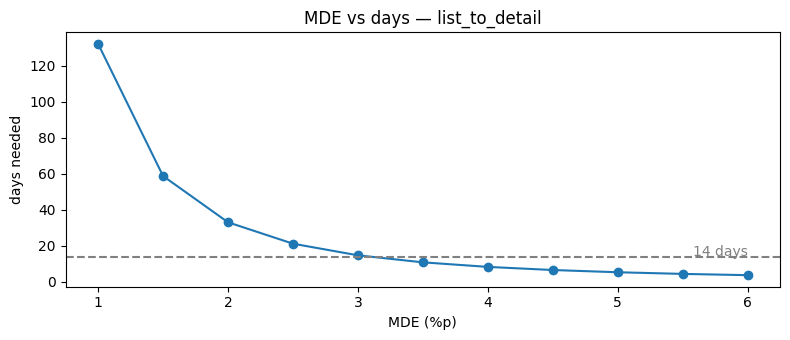

In [ ]:
# [1.5-C] 필요한 기간
# 실험 전 데이터에서 대상 사용자의 하루 평균 '분모 세션 수'를 구하고, 그룹당으로 환산하세요.

num_col, den_col = METRICS[PRIMARY]
daily_denominator = target_pre.groupby("day")[den_col].sum().mean()
TRAFFIC_SHARE = 0.5
daily_per_group = daily_denominator * TRAFFIC_SHARE / 2

n_per_group = n_per_group_naive * design_effect
days_needed = n_per_group / daily_per_group
print(f"그룹당 필요한 분모 세션(디자인 효과 반영): {n_per_group:,.0f}")
print(f"그룹당 하루 분모 세션: {daily_per_group:,.0f} → 계산상 {days_needed:.1f}일")

# MDE를 바꾸면 기간이 어떻게 달라지는지
mdes = np.arange(0.01, 0.061, 0.005)
days = [NormalIndPower().solve_power(proportion_effectsize(p0 + m, p0), alpha=ALPHA, power=POWER) * design_effect / daily_per_group for m in mdes]
plt.figure(figsize=(8, 3.5))
plt.plot(mdes * 100, days, marker="o")
plt.axhline(14, ls="--", c="gray"); plt.text(mdes[-1] * 100, 14.5, "14 days", ha="right", color="gray")
plt.xlabel("MDE (%p)"); plt.ylabel("days needed"); plt.title(f"MDE vs days — {PRIMARY}")
plt.tight_layout(); plt.show()

### Q1.5 표본과 기간

1. A/A 테스트 결과 두 그룹의 차이는 유의했나요? 유의하지 않아야 정상인 이유는?
2. 사용자 단위 표준오차가 세션 독립 가정 표준오차보다 큰 이유를 "같은 사람의 세션"이라는 말을 써서 설명하세요.
3. 계산상 필요한 일수와 **최종으로 정한 실험 기간**은 각각 며칠인가요? 계산값보다 길게 잡았다면 그 이유는?
4. MDE를 어떤 근거로 정했나요? (통계가 아닌 **비즈니스 관점**의 근거를 포함)
5. (선택) `PRIMARY`를 `search_to_complete`로 바꿔 다시 계산해보세요. 기간이 어떻게 달라지나요? 이것이 1.3의 지표 역할 선택에 어떤 의미가 있나요?

**답변:**

1. 유의하지 않았다. 두 그룹의 `list_to_detail` 차이는 0.0007이고 p-value는 0.93이며 신뢰구간(-1.45%p - +1.59%p)이 0을 포함한다. A/A는 처치 없이 같은 화면을 보여준 두 그룹이기 때문에 차이가 없어야 하고, 여기서 유의하게 나오면 분할이나 계산방식을 의심해야 한다. 다만 $\alpha$=0.05이므로 우연히 유의할 확률도 5%라서, 시드를 바꿔 반복했을 때 거짓양성이 5% 안팎인지 보는 게 더 확실하다.

2. 같은 사람의 세션은 행동이 서로 비슷해서 세션 1,000개가 서로 다른 1,000명만큼의 정보를 주지 못한다. 세션을 독립으로 보면 정보가 실제보다 많다고 착각해 표준오차가 작게 나오고(`se_naive` 0.0061), 같은 사람의 세션을 한 묶음으로 보면 실제 흔들림이 반영되어 더 크다(`se_delta` 0.0078). 그 비율의 제곱이 디자인 효과 1.59이며, 필요한 표본이 약 1.6배로 늘어난다는 뜻이다.

3. 계산상 필요한 일수는 `traffic_share = 0.5` 기준으로 약 14.7일이고(1.0이면 7.3일), 최종 기간은 21일(3주)로 정할 것이다. 14일이면 필요 표본을 조금 못 채우고, 7일 단위로 잡으면 평일과 주말이 같은 횟수로 들어가 요일에 따른 쏠림이 없다. 또 날짜별 효과를 비교해 초반에만 효과가 크지 않은지도 확인할 수 있다.

4. 1.2 가설에서 예상한 개선폭 +3 - 5%p 중 가장 작은 3%p를 최소 효과 크기로 정했다. 비즈니스 관점에서는 채널 간 격차 약 10.7%p 중 가격 불일치가 원인인 부분을 약 30%로 가정했을 때의 최소 개선폭이다. 3%p는 상대 약 +6%이며, 이후 단계 전환이 같다면 `search_to_complete`는 13.2% → 약 14.0%, 검색당 매출은 약 23,275원 → 24,730원(+1,455원)에 해당한다. 이보다 작은 개선은 목록 카드 개발·운영 비용과 가격 불일치 위험을 감안하면 실험할 가치가 낮다고 보았다. 또 MDE를 2%p로 낮추면 필요한 기간이 14.7일에서 약 33일(트래픽 50% 기준)로 늘어 현실적이지 않아 3%p로 정했다.

5. 선택 문항 답변 생략



## 1.6 실험 기간 중간에 외부 변화가 생긴다면?

마케팅팀에서 연락이 왔습니다. **실험 8일차부터 promotion 채널 대규모 광고 캠페인이 시작**되어 promotion 유입이 크게 늘어납니다.

1. 이 캠페인은 A그룹과 B그룹에 **똑같이** 영향을 줍니다. 그래도 실험 결과 해석에 문제가 생길까요? 무작위 배정의 성질로 설명하세요.
2. 캠페인으로 새로 들어오는 사용자는 평소 promotion 사용자와 어떻게 다를까요? 어떤 지표의 수준이 8일차 전후로 달라질까요?
3. 이 상황에서 설계를 바꾸거나 분석 계획에 추가할 것이 있다면? (캠페인을 피해 실험을 미루거나 줄이는 선택지도 검토)

**답변:**

1. 처치 효과를 측정하는 내적 타당성에는 문제가 없다. 무작위 배정이라면 캠페인으로 유입된 사용자도 A와 B에 같은 비율로 배정되므로, 캠페인의 영향은 두 그룹에 비슷하게 나타나 B − A의 차이에서는 상쇄된다. 다만 캠페인 사용자는 평소 사용자와 특성이 다를 수 있어, 측정된 효과가 전체 사용자의 평균적인 효과와 달라질 가능성은 있다.

2. 대규모 광고로 유입된 사용자는 처음 방문하거나 가볍게 구경하는 경우가 많아 평소보다 구매 의도가 낮을 가능성이 있다. 이 경우 `list_to_detail`과 `search_to_complete`가 낮아질 수 있고, 광고에서 본 할인가와 목록 가격의 불일치로 이탈하는 비율도 달라질 수 있다. detail_to_room 역시 구매 의도가 낮은 사용자가 늘면서 영향을 받을 수 있다. 다만 어느 방향으로 달라지는지는 추측이므로 실제 데이터를 통해 확인해야 한다. 또한 캠페인 시작 후 목록 세션 수가 크게 증가할 수 있으므로 일별 세션 수도 함께 확인한다.

3. 캠페인을 피해 실험을 미루는 것은 권하지 않는다. 캠페인 종료일이 정해지지 않았고 길어질 수 어(21일까지 이어진다고 가정하면 8~21일차 14일간), 이를 피하면 실험 일정이 크게 늦어진다. 대신 주요 지표와 가드레일은 그대로 유지하고 다음과 같이 분석한다.

- 전체 기간의 결과를 주 결과로 사용하되, 1~7일차와 8일차 이후의 효과를 비교한다.

- 신규 사용자와 기존 사용자를 나누어 효과를 비교한다(구분 컬럼이 없으면 실험 전 로그에 없던 사용자를 신규로 근사한다).

- 8일차 이후 두 그룹의 사용자 수 비율이 달라지지 않았는지(SRM)와 신규·기존 사용자 비율이 비슷한지 확인한다.

    구간별 결과는 탐색적으로 해석하고, 효과가 크게 다르면 캠페인 종료 후 평소 트래픽에서 후속 실험을 진행한다.

    실험 기간은 처음부터 늘리지 않고, 8일차 이후 데이터가 쌓인 뒤 표본이 충분한지 다시 확인한다. 특히 신규 사용자는 사용자당 세션 수가 적어 디자인 효과(1.59)가 달라질 수 있으므로 일별 세션 수와 함께 확인한다.

## 1.7 사전 판정 규칙

결과를 보기 **전에** 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

| 상황 | 판정 |
|---|---|
| 데이터 품질(SRM) 검정 p < 0.001 | 결과 해석 보류. 배정·로그 오류 원인을 찾아 고친 뒤 재실험한다. |
| Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음 | 출시. 단계적으로 트래픽을 늘리며 확대한다. |
| Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화 | 출시 보류. 악화 원인(가격 불일치 등)을 분석해 수정한 뒤 재실험한다. |
| Primary 유의하지 않음 | 출시하지 않는다. 효과가 없다고 단정하지는 않고, MDE(3%p)보다 작은 효과일 수 있다고 기록한다. |
| (선택) 그 밖에 미리 정해두고 싶은 규칙 | 8일차 전후(캠페인) 효과의 방향이 서로 반대이면 전 기간 결과로 바로 판정하지 않고, 평소 트래픽에서 후속 실험으로 확인한다. |

In [ ]:
# [1.8] 최종 설계서 — 위에서 정한 값을 그대로 옮기세요. 이 셀이 Part 2의 실험을 결정합니다.

my_design = {
    "idea":           "A",      # "A" | "B" | "C"
    "target":         "promotion",      # "promotion" | "all"
    "unit":           "user",      # "user" | "session"
    "primary_metric": PRIMARY,
    "guardrails":     ["detail_to_room", "search_to_complete", "cancel_rate"],      # 예: ["search_to_complete", "detail_to_room"]
    "secondary":      [],
    "alpha":          ALPHA,
    "power":          POWER,
    "mde_abs":        MDE,
    "traffic_share":  TRAFFIC_SHARE,
    "duration_days":  21,        # 1.5에서 정한 최종 기간 (3~42)
    "stopping":       "fixed",      # "fixed": 정한 기간까지 / "peek": 매일 확인하다 유의하면 중단
}
my_design

{'idea': 'A',
 'target': 'promotion',
 'unit': 'user',
 'primary_metric': 'list_to_detail',
 'guardrails': ['detail_to_room', 'search_to_complete', 'cancel_rate'],
 'secondary': [],
 'alpha': 0.05,
 'power': 0.8,
 'mde_abs': 0.03,
 'traffic_share': 0.5,
 'duration_days': 21,
 'stopping': 'fixed'}

---
# Part 2. 실행과 판정

여기서부터는 Part 1을 수정하지 마세요. 아래 셀을 실행하면 **여러분의 설계대로** 실험이 진행됩니다.

In [ ]:
exp = run_experiment(my_design, SEED)
display(exp.head())

실험 기간: 2026-03-02 ~ 2026-03-22 (21일)
실험에 노출된 사용자: 6,861명 / 세션: 27,045개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


,session_id,user_id,channel,device,user_type,day,session_start,group,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,E00000000,200145,promotion,ios,leisure,1,2026-03-02 11:05:57,B,1,1,0,0,0,0,None,0.0000,0,0.0000
1,E00000001,200148,promotion,web,leisure,1,2026-03-02 18:55:56,B,1,1,1,0,0,0,None,0.0000,0,0.0000
2,E00000002,200478,promotion,android,leisure,1,2026-03-02 11:53:28,B,1,1,0,0,0,0,None,0.0000,0,0.0000
3,E00000003,200479,promotion,android,business,1,2026-03-02 21:25:01,B,1,1,0,0,0,0,None,0.0000,0,0.0000
4,E00000004,200638,promotion,android,leisure,1,2026-03-02 13:10:08,B,1,1,0,0,0,0,None,0.0000,0,0.0000


## 2.1 데이터 품질 — SRM 확인

결과 지표를 보기 전에 **배정 비율이 설계(50:50)대로인지** 먼저 확인합니다.

In [ ]:
from scipy.stats import chisquare

# 주석 빈칸: 배정 단위가 사용자이므로, 그룹별 사용자 수(고유 user_id 개수) 를 세어야 한다.
counts = exp.groupby("group")["user_id"].nunique()
print(counts)

total = counts.sum()
srm_p = chisquare(counts.values, f_exp=[total * 0.5, total * 0.5]).pvalue
print(f"SRM 검정 p-value: {srm_p:.2e}  →  {'SRM 의심! 결과 해석을 멈추세요' if srm_p < 0.001 else '통과'}")

# 어디서 어긋났는지 보기: 기기별 그룹 사용자 수
display(exp.groupby(["device", "group"])["user_id"].nunique().unstack())

group
A    3446
B    3415
Name: user_id, dtype: int64
SRM 검정 p-value: 7.08e-01  →  통과


group,A,B
device,,
android,1432,1395
ios,1308,1277
web,706,743


In [ ]:
# 기기별로 A/B 사용자 수 차이가 우연 범위인지 카이제곱 검정(AI 활용)
for dv in ["android", "ios", "web"]:
    c = exp[exp["device"] == dv].groupby("group")["user_id"].nunique()
    print(dv, c.values, f"p = {chisquare(c.values).pvalue:.3f}")

android [1432 1395] p = 0.486
ios [1308 1277] p = 0.542
web [706 743] p = 0.331


In [ ]:
for name, sub in [("1~7일", exp[exp.day<=7]), ("8일~", exp[exp.day>=8])]:
    c = sub.groupby("group")["user_id"].nunique()
    print(name, c.to_dict(), f"SRM p={chisquare(c.values).pvalue:.3f}")
display(exp.groupby(["day","group"]).size().unstack().T)   # 일별 세션 수

1~7일 {'A': 1987, 'B': 1924} SRM p=0.314
8일~ {'A': 3099, 'B': 3098} SRM p=0.990


day,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
group,,,,,,,,,,,,,,,,,,,,,
A,570,503,488,533,493,533,511,783,712,669,690,697,720,748,766,701,693,735,708,693,655
B,502,479,497,511,496,469,498,701,734,740,730,712,751,698,710,679,710,723,683,720,701


### Q2.1
1. SRM 검정 결과는? 통과하지 못했다면, 기기별 표에서 어디가 어긋났나요?
2. SRM이 있을 때 결과를 그대로 믿으면 안 되는 이유는? "어떤 사용자가 빠졌는가"의 관점에서 설명하세요.

**답변:**

1. 통과했다. A는 3,446명, B는 3,415명으로 50:50 기대값인 3,430.5명과 약 15명 차이이며, p-value는 0.71로 0.001보다 훨씬 크다. 따라서 두 그룹의 차이는 우연한 범위로 판단한다. 기기별로도 Android(1,432 / 1,395), iOS(1,308 / 1,277), Web(706 / 743) 모두 큰 차이가 없다. 기기별로 카이제곱 검정을 해 보니 p-value는 Android 0.49, iOS 0.54, Web 0.33으로 모두 0.001보다 훨씬 커서 우연한 범위로 판단한다. 따라서 SRM 문제는 없으며, 1.7의 기준에 따라 Primary와 가드레일 분석으로 넘어간다.

2. SRM은 무작위 배정 이후 특정 사용자나 유형의 사용자가 한쪽 그룹에서 더 많이 빠졌다는 신호다. 예를 들어 실험군 화면의 오류로 특정 기기 사용자의 로그가 누락되었다면, B에는 오류 없이 화면을 본 사용자만 남게 된다. 이 경우 B와 A의 차이에는 처치 효과뿐 아니라 사용자 구성의 차이도 섞인다. 따라서 지표가 개선되더라도 실제로 화면의 효과인지, 특정 사용자가 빠진 영향인지 구분하기 어려워진다.

## 2.2 지표 분석

`ratio_test(df, metric)`은 두 가지 표준오차를 함께 보여줍니다.
- `se_naive`, `p_naive`: 세션을 서로 독립인 관측으로 본 계산
- `se_delta`, `p_value`, `ci_low ~ ci_high`: 같은 사용자의 세션끼리 묶어서 계산 (**판정에는 이쪽을 사용**)

In [ ]:
# [2.2-A] Primary + Guardrail + Secondary 결과표
metrics_to_check = [my_design["primary_metric"]] + my_design["guardrails"] + my_design["secondary"]

results = pd.DataFrame([ratio_test(exp, m) for m in metrics_to_check])
display(results)

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,list_to_detail,0.4336,0.4611,0.0275,0.0633,0.0096,0.0454,0.0026,0.0091,0.0063,0.0000
1,detail_to_room,0.6781,0.6691,-0.0090,-0.0132,-0.0279,0.0100,0.3545,0.0097,0.0089,0.3130
2,search_to_complete,0.1157,0.1167,0.0011,0.0091,-0.0083,0.0104,0.8260,0.0048,0.0039,0.7870
3,cancel_rate,0.0884,0.0733,-0.0151,-0.1706,-0.0339,0.0037,0.1158,0.0096,0.0097,0.1212


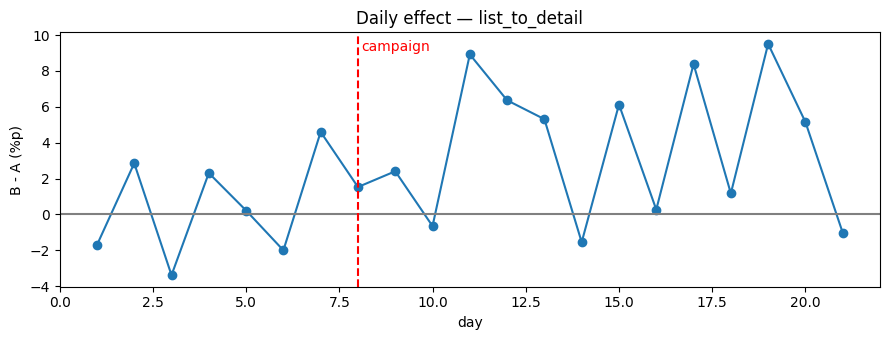

1~7일: diff=+0.0041, 95% CI [-0.0235, +0.0317]
8일~: diff=+0.0369, 95% CI [+0.0177, +0.0560]


In [ ]:
# [2.2-B] 일별 Primary 효과 — 신규성 효과와 8일차(캠페인 시작) 전후 확인
num_col, den_col = METRICS[my_design["primary_metric"]]
daily = exp.groupby(["day", "group"]).agg(num=(num_col, "sum"), den=(den_col, "sum")).reset_index()
daily["rate"] = daily["num"] / daily["den"]

# 주석 빈칸: pivot 후 B - A를 계산하면 그날 하루의 처치효과(실험군과 대조군의 primary 차이) 를 볼 수 있다.
daily_diff = daily.pivot(index="day", columns="group", values="rate")
daily_diff["diff"] = daily_diff["B"] - daily_diff["A"]

plt.figure(figsize=(9, 3.5))
plt.plot(daily_diff.index, daily_diff["diff"] * 100, marker="o")
plt.axhline(0, c="gray"); plt.axvline(8, ls="--", c="red"); plt.text(8.1, plt.ylim()[1] * 0.9, "campaign", color="red")
plt.xlabel("day"); plt.ylabel("B - A (%p)"); plt.title(f"Daily effect — {my_design['primary_metric']}")
plt.tight_layout(); plt.show()

# 전반부(1~7일) vs 후반부(8일~) 효과
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, my_design["primary_metric"])
    print(f"{name}: diff={r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

In [ ]:
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, "list_to_detail")
    print(f"{name}: A={r['A']:.4f}, B={r['B']:.4f}")

1~7일: A=0.5036, B=0.5077
8일~: A=0.4081, B=0.4450


In [ ]:
de_real = (results.loc[0, "se_delta"] / results.loc[0, "se_naive"]) ** 2
print(f"실제 실험 디자인 효과: {de_real:.2f}")
print(f"이 값으로 다시 계산한 필요 일수: {n_per_group_naive * de_real / daily_per_group:.1f}일")

실제 실험 디자인 효과: 2.11
이 값으로 다시 계산한 필요 일수: 19.4일


In [ ]:
for D in [14, 21]:
    r = ratio_test(aa_split(target_pre[target_pre["day"] <= D], seed=SEED), PRIMARY)
    print(D, (r["se_delta"] / r["se_naive"]) ** 2)

14 1.5910641631698041
21 1.8910692911970484


In [ ]:
# 사전 등록하지 않은 Secondary 지표 — 사후 확인이므로 탐색적으로만 해석
display(pd.DataFrame([ratio_test(exp, m) for m in ["checkout_to_complete", "revenue_per_search"]]))

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,checkout_to_complete,0.7060,0.7017,-0.0043,-0.0061,-0.0311,0.0225,0.7526,0.0137,0.0137,0.7523
1,revenue_per_search,"19,996.6179","20,338.3666",341.7487,0.0171,"-1,413.2756","2,096.7729",0.7027,895.4370,748.1746,0.6478


In [ ]:
# 두 구간 효과의 차이 검정
r1 = ratio_test(exp[exp.day<=7], PRIMARY); r2 = ratio_test(exp[exp.day>=8], PRIMARY)
dd = r2["diff"] - r1["diff"]; se = (r1["se_delta"]**2 + r2["se_delta"]**2) ** 0.5
print(f"효과 차이(8일~ − 1~7일): {dd:+.4f}, 95% CI [{dd-1.96*se:+.4f}, {dd+1.96*se:+.4f}]")

효과 차이(8일~ − 1~7일): +0.0328, 95% CI [-0.0008, +0.0663]


### Q2.2
1. Primary의 효과를 **점추정이 아니라 신뢰구간으로** 한 문장으로 말하세요. (예: "목록 → 상세 전환율이 ○%p에서 ○%p 사이로 올랐다")
2. `se_naive`와 `se_delta` 중 어느 쪽이 더 큰가요? naive로 판정했다면 어떤 위험이 있나요?
3. 일별 그래프에서 효과가 기간 내내 비슷한가요, 아니면 초반에 몰려 있나요? 어떤 의미인가요?
4. Guardrail 지표는 어떻게 나왔나요? "유의한 악화 없음"과 "변화 없음이 증명됨"은 같은 말인가요?
5. A그룹과 B그룹의 Primary 지표 **수준**이 8일차 전후로 어떻게 달라졌나요? 그런데도 A/B 비교가 유효한 이유는?

**답변:**

1. 할인가 표시로 목록 → 상세 전환율이 대조군보다 약 1.0%p에서 4.5%p 사이(95% 신뢰구간, 점추정 +2.75%p) 올랐다.

2. `se_delta`(0.0091)가 `se_naive`(0.0063)보다 크며, 제곱비는 약 2.1이다. 같은 사용자의 여러 세션을 독립적인 관측치로 보는 `naive` 방식은 표준오차를 실제보다 작게 추정한다. 그 결과 p-value가 지나치게 작아지고 신뢰구간도 좁아져, 실제보다 효과가 확실한 것처럼 판단할 위험이 있다.

3. 효과는 초반보다 8일차 이후에 더 크게 나타난다. 1-7일차는 +0.41%p로 신뢰구간이 0을 포함하지만, 8일차 이후는 +3.69%p이고 신뢰구간은 +1.77 - +5.60%p이다. 따라서 초반에 효과가 크다가 점차 줄어드는 신기함 효과와는 다른 패턴이다. 다만 두 구간 효과의 차이는 +3.28%p(95% CI −0.08~+6.63%p)로 0을 포함하므로 효과가 실제로 달라졌다고 단정할 수는 없다. 캠페인 사용자가 가격 불일치에 더 민감했다는 해석 역시 사후 추측이므로 탐색적 결과로만 본다.

4. 세 가드레일 모두 통계적으로 유의한 악화는 없었다. detail_to_room은 -0.9%p(p=0.35), search_to_complete는 +0.1%p(p=0.83), cancel_rate는 -1.5%p(p=0.12)이다. 그러나 유의하지 않다는 것은 변화가 없다는 뜻이 아니라, 차이가 있다고 판단할 충분한 근거가 없다는 의미다. 특히 detail_to_room은 신뢰구간상 최대 -2.8%p 하락 가능성도 배제할 수 없다. 따라서 1.7의 유의한 악화 기준으로는 통과하지만, 출시 후에도 해당 지표를 지속적으로 모니터링한다. `search_to_complete`도 CI가 −0.83~+1.04%p라 최종 전환이 개선됐다고도, 악화되지 않았다고도 단정하기 어렵다. (`cancel_rate`는 점추정상 감소지만 CI가 0을 포함한다.)

5. 8일차 이후 list_to_detail은 A가 50.4% → 40.8%, B가 50.8% → 44.5%로 모두 하락했다. 캠페인으로 유입된 사용자가 평소 promotion 사용자보다 상세 페이지로 덜 이동했기 때문일 가능성이 있지만, 이는 추측이므로 단정할 수 없다. 다만 무작위 배정으로 캠페인 사용자가 두 그룹에 비슷하게 섞여 있고, 같은 기간의 A/B를 비교하므로 캠페인 자체의 영향은 두 그룹 간 차이에서 어느 정도 상쇄된다. 또한 전체뿐 아니라 1-7일(p=0.31)과 8일 이후(p=0.99)에서도 SRM을 통과했으므로 A/B 비교 자체는 유효하다.

## 2.3 판정

1.7의 사전 판정 규칙을 그대로 적용하세요.

- **해당하는 규칙 행:** Primary가 유의하게 개선되고, 모든 Guardrail에서 유의한 악화가 없음
- **판정:** 배포
- **결정 메모 (3~5문장):** 목록 카드에 할인가를 표시한 결과 목록 → 상세 전환율이 대조군보다 +2.75%p(95% CI +0.96~+4.54%p) 높았고, 가드레일에서 유의한 악화가 없어 사전 판정 규칙에 따라 배포한다. 점추정은 MDE(3%p)에 약간 못 미쳤지만 CI가 MDE를 포함하며, 사전 규칙이 점추정의 하한을 정하지 않았다는 점은 다음 설계의 보완점으로 기록한다. 다만 최종 전환(`search_to_complete`)은 +0.11%p(CI −0.83 - +1.04%p)로 개선이 확인되지 않았고, 사후 확인한 `revenue_per_search`도 유의하지 않아(+342원, CI −1,413 - +2,097원) 클릭 증가가 예약·매출 증가로 이어졌다고는 말할 수 없다. `detail_to_room`은 최대 −2.8%p까지 하락했을 가능성을 배제하지 못했으므로 단계적으로 확대하며 이 세 지표를 모니터링한다. 이 해석은 처방 ①(총액 표시)이 실험 전에 배포되었다는 가정에 기반한다.
- **다음 실험 아이디어 (1개):** 할인가 표시는 첫 방문 promotion 사용자에게 더 큰 효과가 있을 가능성이 있다. 8일차 이후 캠페인 신규 유입이 증가한 시점에서 효과가 더 크게 나타났기 때문이다. 다만 1~7일(+0.41%p)과 8일 이후(+3.69%p)의 두 구간 효과 차이의 CI가 0을 포함해 차이가 확실하지 않고, 실험 후 사후적으로 구분한 결과이므로 근거가 약하다. 그래서 다음 실험에서는 로그에 첫 방문 플래그를 추가해(현재 데이터에는 신규/기존 구분 컬럼이 없다) 사전에 구분한 뒤 효과 차이를 검증한다.

---
# Part 3. 심화 과제 — 아래 중 1개 선택

같은 사용자 데이터로 **설계 한 가지만 바꿔** 다시 실험하고, 결과가 왜 달라졌는지 분석하세요.

| 선택 | 바꿀 것 | 생각해볼 질문 |
|---|---|---|
| **A. 기간과 중단 규칙** | `duration_days`를 7로, 또는 `stopping`을 `"peek"`으로 | 언제 멈췄나? 효과 크기가 어떻게 달라졌나? 왜? |
| **B. 대상 범위** | `target`을 반대로 | 효과 크기와 표준오차가 어떻게 달라졌나? 어느 쪽이 의사결정에 유리한가? |
| **C. 배정 단위** | `unit`을 반대로 | 효과 크기가 왜 달라졌나? 사용자 경험 측면의 문제는? |

### 심화 과제 작성
- 선택한 항목: A. 기간과 중단 규칙
- 바꾼 설계 값: `stopping`을 `"fixed"`에서 `"peek"`으로
- 원래 결과 vs 바뀐 결과 (핵심 숫자 2~3개):
  - 기간: 21일 → 12일에 조기 종료 (계산상 필요한 14.7일보다도 짧음)
  - `list_to_detail` 효과: +2.75%p(95% CI +0.96 - +4.54%p) → +1.90%p(95% CI -0.26 - +4.06%p)
  - 사용자 단위 p-value: 0.0026 → 0.084 (세션 독립 가정의 p_naive는 0.029)
- 왜 달라졌는가: 12일 만에 중단하면서 표본이 줄어 신뢰구간이 넓어졌고(-0.26~+4.06%p), 효과가 더 컸던 8일차 이후 데이터도 5일치만 포함되었다. 시뮬레이터 코드(`run_experiment`)를 보면 peek은 3일차부터 매일 세션을 독립 관측으로 본 검정을 하고 p < 0.05이면 멈추도록 되어 있다. 실제로 12일차에 세션 독립 가정의 p_naive는 0.029로 기준을 넘어 멈췄지만, 사용자 단위 p-value는 0.084로 유의하지 않았다. 같은 사용자의 세션을 독립으로 보는 검정이 표준오차를 작게 계산해서 실제보다 일찍 유의하다고 판단하고 멈춘 사례이며, 이번 한 번의 결과만으로 거짓 양성이었다고 단정할 수는 없다. 또한 peek은 매일 검정을 반복하므로 한 번만 보는 fixed보다 거짓 양성 확률이 5%보다 커진다. 이번에는 이 반복 검정과, 사용자 단위 분석과 다른 세션 독립 가정 검정이 겹쳐 조기 종료됐다.
- 실무에서 이 교훈을 적용한다면: 중단 기준은 최종 분석과 같은 사용자 단위로 정하고, 정해진 기간까지 진행한 뒤 한 번 판정하는 fixed 방식을 기본으로 한다. 조기 중단이 필요하다면 순차 검정을 사전에 설계한다.

In [ ]:
# [심화 과제 Skeleton]
alt_design = dict(my_design)
alt_design["stopping"] = "peek"      # 바꿀 설계 하나

alt = run_experiment(alt_design, SEED)
alt_results = pd.DataFrame([ratio_test(alt, m) for m in metrics_to_check])
display(pd.concat({"원래 설계": results.set_index("metric"), "바꾼 설계": alt_results.set_index("metric")}, axis=1))

실험 기간: 2026-03-02 ~ 2026-03-13 (12일 · 중간 확인 규칙으로 조기 종료)
실험에 노출된 사용자: 5,501명 / 세션: 14,251개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


원래 설계                                                  \
                        A      B    diff rel_diff  ci_low ci_high p_value   
metric                                                                      
list_to_detail     0.4336 0.4611  0.0275   0.0633  0.0096  0.0454  0.0026   
detail_to_room     0.6781 0.6691 -0.0090  -0.0132 -0.0279  0.0100  0.3545   
search_to_complete 0.1157 0.1167  0.0011   0.0091 -0.0083  0.0104  0.8260   
cancel_rate        0.0884 0.0733 -0.0151  -0.1706 -0.0339  0.0037  0.1158   

                                              바꾼 설계                          \
                   se_delta se_naive p_naive      A      B    diff rel_diff   
metric                                                                        
list_to_detail       0.0091   0.0063  0.0000 0.4537 0.4727  0.0190   0.0420   
detail_to_room       0.0097   0.0089  0.3130 0.6845 0.6696 -0.0149  -0.0218   
search_to_complete   0.0048   0.0039  0.7870 0.1213 0.1225  0.0012   0.0102   
cancel_rate          0.0096   0.0097  0.1212 0.0861 0.0751 -0.0111  -0.1283   

                                                                      
                    ci_low ci_high p_value se_delta se_naive p_naive  
metric                                                                
list_to_detail     -0.0026  0.0406  0.0842   0.0110   0.0087  0.0289  
detail_to_room     -0.0397  0.0099  0.2383   0.0127   0.0120  0.2140  
search_to_complete -0.0110  0.0134  0.8432   0.0062   0.0055  0.8223  
cancel_rate        -0.0363  0.0142  0.3907   0.0129   0.0131  0.3977

---
# Part 4. 회고

- 설계 단계에서 가장 고민했던 결정과 그 이유:

개선 아이디어를 A, B, C 중 무엇으로 할지가 가장 고민이었다. 처음에는 눈에 띄는 걸 고르려 했지만, 퍼널에서 격차가 목록 → 상세 한 곳에만 있고 상세 이후 단계는 다른 채널과 대체로 비슷하다는 사실은 A·B·C 모두와 맞았다. 그중 가격을 바꾸지 않고 광고 가격 불일치라는 가설이 가장 구체적이어서 A로 정했다.

- 결과를 보고 "설계를 바꾸고 싶다"고 느낀 순간이 있었나요? 있었다면 무엇이었나요?

점추정 +2.75%p가 예상 하단(+3%p)보다 약간 낮게 나와서(CI +0.96~+4.54%p는 예상 범위를 포함) MDE나 가설 범위를 고치고 싶다고 생각하기도 했다. 하지만 Part 1은 결과 전의 약속이라 고치지 않고 "점추정이 예상 하단보다 약간 낮았다"고 기록했다. 심화 과제에서 peek으로 바꿨을 때 결론이 뒤집힌 것을 보고, 사전 약속과 중단 규칙이 왜 필요한지 실감했다.

- 진단 결과를 실험으로 검증해보며 새로 알게 된 점 (다음 그로스 세션에서는 이런 진단을 직접 하는 법을 배웁니다):

  - 채널별 퍼널 분석으로 어디서 이탈하는지 찾아낸 진단(목록 → 상세 격차)을 실험으로 확인할 수 있었고, 효과는 격차 10.7%p 전부가 아니라 일부(약 2.75%p)였다.
  - 배정이 사용자 단위라 세션을 독립으로 볼 때보다 분산이 커진다. 디자인 효과(분산 배수)는 A/A(14일)에서 1.59, 실제 21일 실험에서 2.11이었고, 표준오차로는 각각 약 1.26배, 1.45배다. A/A도 기간이 길수록 커져(14일 1.59, 21일 1.89), 사용자당 세션이 늘수록 디자인 효과가 커진다. 2.11로 다시 계산한 필요 일수는 19.4일이라 21일 설계는 충분했다.
  - 가드레일이 "유의한 악화 없음"이어도 변화가 없다는 증명은 아니다(detail_to_room은 최대 약 -2.8%p까지 배제하지 못했다).
  - 같은 설계에서 중단 방식만 바꿔도(21일 fixed → 12일 peek) 결론이 뒤집힐 수 있다.
  - 캠페인 같은 외부 변화는 A/B 비교 자체는 깨지 않지만, 효과의 일반화에는 영향을 준다.

- 가장 어려웠던 부분:

`traffic_share`(실험에 들어오는 비율)와 대조군:실험군 50:50 분할이 서로 다른 개념이라는 걸 구분하는 것이었다. 또 사전 설계 단계에서 표본 수, 기간, 가드레일 허용 폭처럼 결과를 보기 전에 숫자를 정하는 일이 어려웠다.

---
# Part 5. 제출 전 체크리스트

- [x] Q0에서 실험이 필요한 처방과 바로 고쳐야 하는 처방을 구분했는가?
- [x] 가설에 바꾸는 것, 행동 메커니즘, 지표와 방향이 모두 있는가?
- [x] 모든 지표의 분자 / 분모 / Grain / Window를 명시했는가?
- [x] 배정 단위와 분석 단위의 차이를 고려했는가? (A/A 테스트, 디자인 효과)
- [x] MDE를 비즈니스 근거로 정했고, 기간을 계산값보다 짧지 않게 정했는가?
- [x] 판정 규칙을 결과를 보기 전에 정했고, 결과를 본 뒤 Part 1을 수정하지 않았는가?
- [x] SRM을 가장 먼저 확인했는가?
- [x] 효과를 신뢰구간으로 말했는가?
- [x] 기술블로그에 옮길 설계서, 그래프, 결정 메모를 정리했는가?
- [x] 마지막 셀에 AI 활용 방법과 대화 내역을 붙였는가?

---
# Part 6. 생성형 AI 활용 방법 + 대화 내역 (필수)

AI를 사용했다면 아래를 작성하고, **대화 내역을 붙여넣으세요.** 사용하지 않았다면 "사용하지 않음"이라고 적어주세요.

1. 어느 문항에서, 어떤 목적으로 AI를 썼나요?

    1.4-C의 traffic_share(트래픽 투입 비율)를 정할 때 AI를 썼다. 0.5와 0.7 중 무엇이 맞는지 묻고, traffic_share와 실험군:대조군 50:50 분할이 서로 다른 개념인지 확인했으며, 50:50이 검정력이 가장 높은 이유를 설명받아 이유 문장을 쓰는 데 활용했다.
    + 카이제곱 검정 수행 코드를 AI를 활용하여 작성했다.


2. AI의 답 중 **본인 데이터로 확인해보니 틀렸거나 맞지 않았던 것**이 있었나요?

    처음 답변에 이 단계에서 필요하지 않은 표본 수 계산(군당 4,400·6,500·13,000세션)이 들어 있었고, AI가 직접 계산한 게 아니라 손으로 한 근사치였으며 6,500은 근거가 없는 숫자였다. 또 “50% 투입”과 "대조군은 안전지대"를 섞어 써서 개념이 헷갈렸고, 내가 되물어서 traffic_share와 50:50 분할을 구분해 다시 썼다. 이후 1.5-C 셀의 daily_per_group = daily_denominator * TRAFFIC_SHARE / 2 식으로 traffic_share가 "대상 중 실험 참여 비율, 그 안에서 반반"이라는 설명이 맞는지 확인했다. TRAFFIC_SHARE가 1.0으로 남아 있던 것도 0.5로 바꿔서, 계산상 필요한 일수가 7.3일에서 14.7일로 달라지는 것을 확인했다(최종 실험 기간은 이보다 길게 21일로 정했다).


3. 이번 과제에서 AI에게 맡길 수 없었던, **사람이 직접 판단해야 했던 결정**은 무엇이었나요?

    traffic_share를 얼마로 할지 내가 정했다. AI는 정답이 없고 위험(영향받는 사용자 수)과 표본 속도 사이의 절충이라고 설명했으며, 0.5와 0.7 두 버전을 보고 0.5로 정했다.

### 대화 내역
> **나**: 트래픽 투입 비율(traffic_share)을 정해야 하는데, 어떤 기준으로 정하면 좋을까요? 일단 0.5랑 0.7을 생각해 봤는데, 둘 중에 어떤 값이 더 적절할지 고민입니다. 참고로 이번 실험은 가격 표시 방식을 변경하는 실험입니다.

> **AI**: 두 값 모두 선택할 수 있지만, 우선 실험의 위험도와 필요한 표본 수집 속도를 기준으로 판단하시는 게 좋겠습니다.
> traffic_share는 전체 대상 트래픽 중 실험에 참여시킬 비율을 의미합니다. 예를 들어 0.5라면 대상 트래픽의 50%를 실험에 투입하고, 0.7이라면 70%를 투입하는 것입니다.
> 이번처럼 가격 표시 방식을 변경하는 실험은 사용자에게 노출되는 정보가 달라지기 때문에, 변경 사항에 문제가 생겼을 때 영향을 받는 사용자의 규모도 고려해야 합니다. 그런 점에서는 0.5가 조금 더 보수적인 선택이고, 0.7은 실험 데이터를 더 빠르게 확보할 수 있다는 장점이 있습니다.

> **나**: 그러면 일단 안전하게 0.5로 시작하겠습니다. 그런데 대조군과 실험군을 50:50으로 나누는 것과 traffic_share를 0.5로 설정하는 것은 정확히 어떤 차이가 있나요?

> **AI**: 두 설정은 서로 다른 단계에서 적용되는 비율입니다.
> traffic_share = 0.5: 전체 대상 트래픽 중 50%를 실험에 참여시킬지 결정합니다.
> 대조군:실험군 = 50:50: 실험에 참여한 트래픽을 대조군과 실험군에 각각 절반씩 배정합니다.    
> 예를 들어 전체 대상 트래픽이 10만 명이라면, traffic_share = 0.5로 설정했을 때 실험에 참여하는 사용자는 약 5만 명입니다. 이 사용자들을 다시 50:50으로 나누면 대조군 2만 5천 명, 실험군 2만 5천 명이 됩니다.
> 즉, 전체 대상 트래픽 기준으로 보면 대조군과 실험군은 각각 25%씩 차지하게 됩니다. 일반적으로 두 그룹의 분산이 비슷하고 비용도 동일하다면 50:50 배분이 통계적 검정력 측면에서 효율적입니다.
> 따라서 이번 실험에서는 traffic_share = 0.5, 대조군:실험군 = 50:50으로 시작하시는 방안을 추천드립니다. 실험 중 주요 지표와 오류율을 확인한 뒤, 문제가 없고 더 빠른 데이터 수집이 필요하다면 트래픽 비율을 높이는 것도 고려할 수 있습니다.